In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# 1. Définition de l'architecture du CNN Optimisé
def build_optimized_model():
    model = models.Sequential([
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),

        # Bloc 1
        layers.Conv2D(32, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Bloc 2
        layers.Conv2D(64, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Bloc 3
        layers.Conv2D(128, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Bloc 4
        layers.Conv2D(256, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Classification
        layers.Flatten(),
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

tf.keras.backend.clear_session()
opt_model = build_optimized_model()
opt_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,828,481 (37.49 MB)

 Trainable params: 9,827,009 (37.49 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [21]:
# 2. Compilation du modèle avec Adam
opt_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# 3. Configuration des Callbacks d'optimisation
callbacks_opt = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint(filepath='best_optimized_cnn_model.keras', monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

In [22]:
# 4. Entraînement du modèle
HISTORY_EPOCHS = 5

history_opt = opt_model.fit(
    train_generator,
    epochs=HISTORY_EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks_opt
)

Epoch 1/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.7037 - auc: 0.7684 - loss: 0.6738
Epoch 1: val_loss improved from None to 0.26276, saving model to best_optimized_cnn_model.keras

Epoch 1: finished saving model to best_optimized_cnn_model.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 218s 298ms/step - accuracy: 0.7487 - auc: 0.8269 - loss: 0.5724 - val_accuracy: 0.8973 - val_auc: 0.9534 - val_loss: 0.2628 - learning_rate: 1.0000e-05
Epoch 2/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.8217 - auc: 0.9015 - loss: 0.4176
Epoch 2: val_loss improved from 0.26276 to 0.24936, saving model to best_optimized_cnn_model.keras

Epoch 2: finished saving model to best_optimized_cnn_model.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 200s 284ms/step - accuracy: 0.8304 - auc: 0.9092 - loss: 0.4019 - val_accuracy: 0.8975 - val_auc: 0.9718 - val_loss: 0.2494 - learning_rate: 1.0000e-05
Epoch 3/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.8605 - auc: 0.9321 - loss: 0.3463
Epoch 3:

In [ ]:
# Charger les meilleurs poids sauvegardés
print("Chargement des meilleurs poids du modèle...")
opt_model.load_weights('best_optimized_cnn_model.keras')


print("Calcul des prédictions sur l'entraînement...")
y_train_pred_prob = opt_model.predict(train_eval_generator)
y_train_pred = (y_train_pred_prob > 0.5).astype(int).flatten()

print("Calcul des prédictions sur la validation...")
y_val_pred_prob = opt_model.predict(val_generator)
y_val_pred = (y_val_pred_prob > 0.5).astype(int).flatten()

Chargement des meilleurs poids du modèle...
Calcul des prédictions sur l'entraînement...
702/702 ━━━━━━━━━━━━━━━━━━━━ 91s 129ms/step
Calcul des prédictions sur la validation...
106/106 ━━━━━━━━━━━━━━━━━━━━ 14s 131ms/step


In [25]:
# Afficher à nouveau les rapports de classification corrigés
print("="*60)
print("RAPPORT DE CLASSIFICATION CORRIGÉ - ENTRAÎNEMENT")
print("="*60)
print(classification_report(y_train_true, y_train_pred, target_names=target_names))

print("\n" + "="*60)
print("RAPPORT DE CLASSIFICATION CORRIGÉ - VALIDATION")
print("="*60)
print(classification_report(y_val_true, y_val_pred, target_names=target_names))

RAPPORT DE CLASSIFICATION CORRIGÉ - ENTRAÎNEMENT
               precision    recall  f1-score   support

Non-COVID (0)       0.93      0.97      0.95     11231
    COVID (1)       0.97      0.92      0.94     11231

     accuracy                           0.94     22462
    macro avg       0.95      0.94      0.94     22462
 weighted avg       0.95      0.94      0.94     22462


RAPPORT DE CLASSIFICATION CORRIGÉ - VALIDATION
               precision    recall  f1-score   support

Non-COVID (0)       0.97      0.96      0.97      2808
    COVID (1)       0.83      0.86      0.84       579

     accuracy                           0.95      3387
    macro avg       0.90      0.91      0.91      3387
 weighted avg       0.95      0.95      0.95      3387



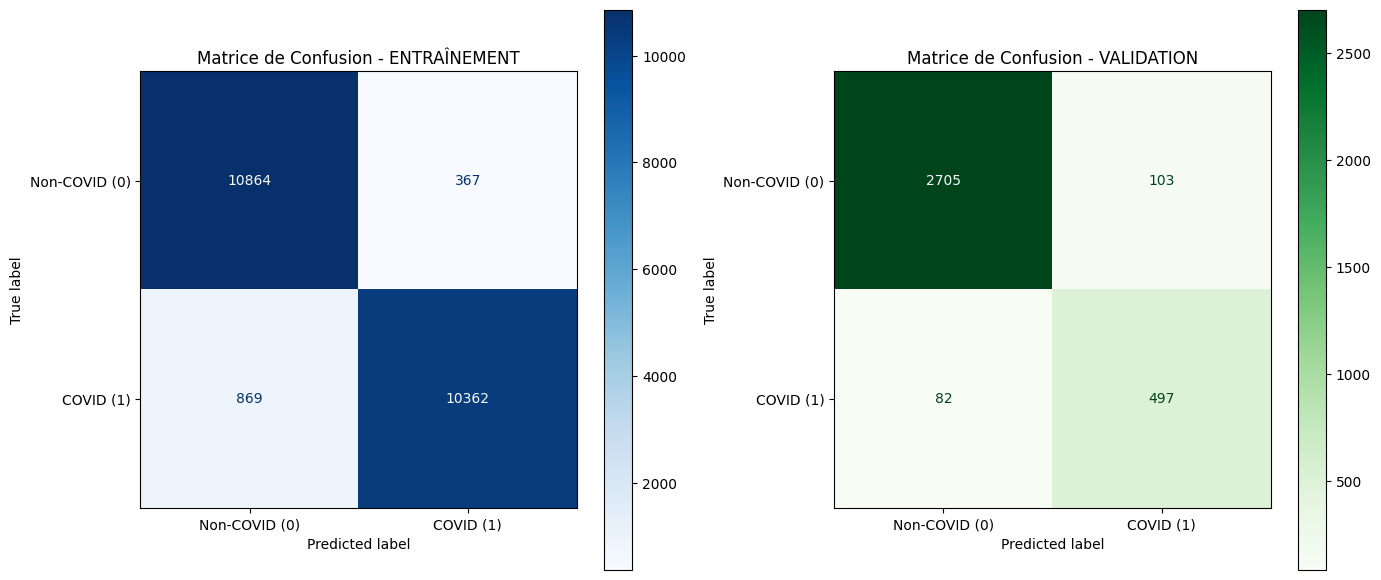

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Configuration des labels pour la visualisation
target_names = ['Non-COVID (0)', 'COVID (1)']

# Création d'une figure avec deux sous-graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Matrice de confusion pour l'entraînement
cm_train = confusion_matrix(y_train_true, y_train_pred)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=target_names)
disp_train.plot(ax=axes[0], cmap=plt.cm.Blues, values_format='d')
axes[0].set_title("Matrice de Confusion - ENTRAÎNEMENT")

# 2. Matrice de confusion pour la validation
cm_val = confusion_matrix(y_val_true, y_val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=target_names)
disp_val.plot(ax=axes[1], cmap=plt.cm.Greens, values_format='d')
axes[1].set_title("Matrice de Confusion - VALIDATION")

plt.tight_layout()
plt.show()

In [ ]:
# INTERPRETABITE DU MODELE CNN

In [31]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Pour un modèle Sequential Keras 3, nous pouvons reconstruire dynamiquement un modèle fonctionnel
    # pour obtenir les tenseurs d'entrées et de sorties requis par Grad-CAM
    input_tensor = model.inputs[0]

    # On parcourt les couches pour recréer le graphe jusqu'aux sorties voulues
    x = input_tensor
    conv_output = None

    for layer in model.layers:
        x = layer(x)
        if layer.name == last_conv_layer_name:
            conv_output = x

    # Créer le modèle fonctionnel d'extraction de gradients
    grad_model = tf.keras.models.Model(inputs=[input_tensor], outputs=[conv_output, x])

    # Calculer les gradients
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Gradients de la classe cible par rapport à la sortie de la couche de conv
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # Vecteur de poids (moyenne globale du gradient par canal)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Pondérer la sortie de la couche de conv par les gradients
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normaliser la heatmap entre 0 et 1 (appliquer ReLU)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    # Charger l'image originale
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))

    # Redimensionner la heatmap à la taille de l'image originale
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # Convertir la heatmap en RGB avec une colormap (Jet)
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    # Superposer la heatmap sur l'image originale
    superimposed_img = heatmap_color * alpha + img * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

    # Visualisation côte à côte
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(img)
    axes[0].set_title("Image originale (Radiographie)")
    axes[0].axis("off")

    axes[1].imshow(heatmap_resized, cmap='jet')
    axes[1].set_title("Carte d'activation (Heatmap)")
    axes[1].axis("off")

    axes[2].imshow(superimposed_img)
    axes[2].set_title("Superposition Grad-CAM")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

Dernière couche de convolution identifiée : conv2d_3


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 1))
  warnings.warn(msg)


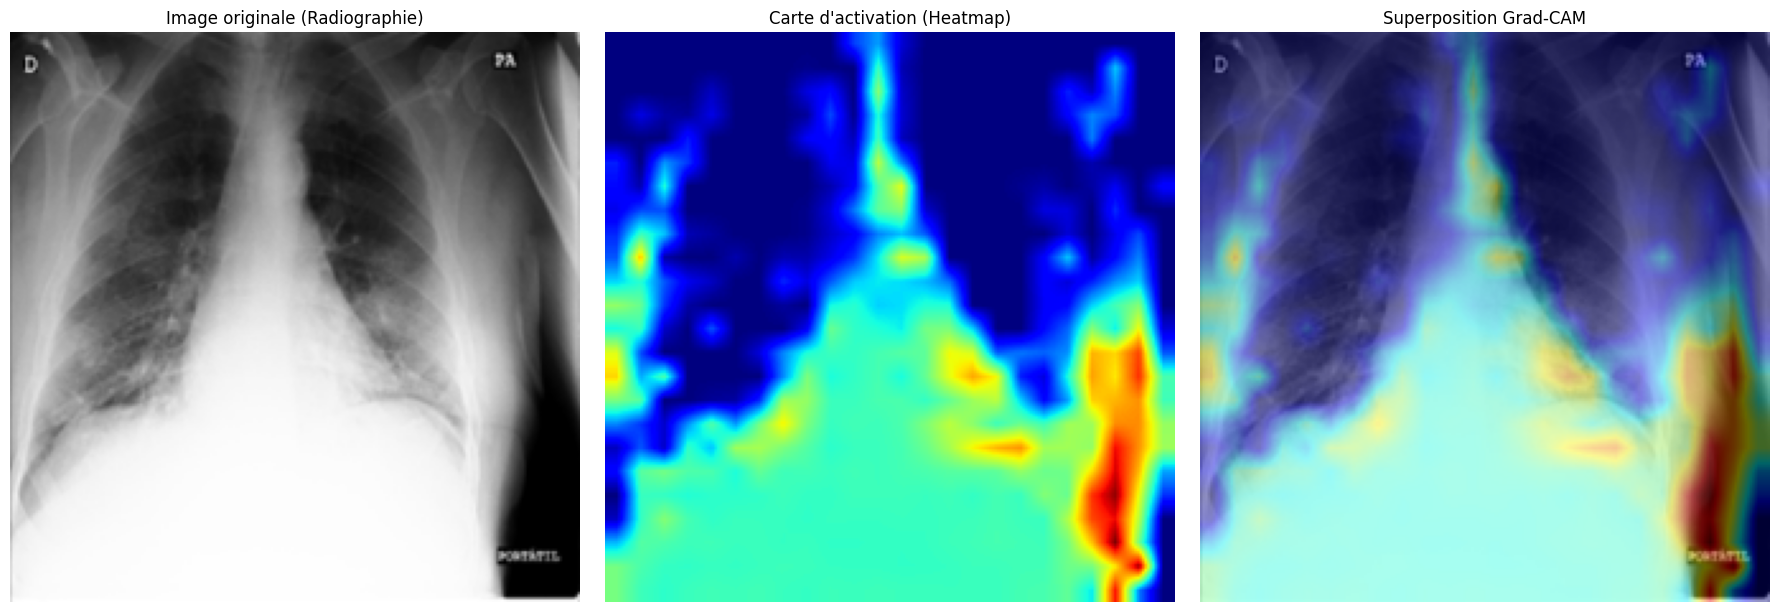

In [ ]:

covid_samples = val_gen_df[val_gen_df["target_str"] == "1"]
if not covid_samples.empty:
    sample_path = covid_samples.iloc[0]["filepath"]

    # Préparer l'image pour le modèle
    img = tf.keras.preprocessing.image.load_img(sample_path, target_size=(224, 224), color_mode="grayscale")
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # S'assurer que le modèle est appelé une fois sur des données réelles
    _ = opt_model(img_array)

    # Déterminer le nom de la dernière couche de convolution
    last_conv_layer_name = [layer.name for layer in opt_model.layers if "conv2d" in layer.name][-1]
    print(f"Dernière couche de convolution identifiée : {last_conv_layer_name}")

    # Générer la heatmap avec la méthode robuste de reconstruction
    heatmap = make_gradcam_heatmap(img_array, opt_model, last_conv_layer_name)

    # Afficher la superposition Grad-CAM
    display_gradcam(sample_path, heatmap)
else:
    print("Aucun échantillon COVID trouvé dans le dataset de validation pour le test.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Image sélectionnée : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/Normal/images/Normal-7628.png
Prédiction du modèle : 0.0087 -> Classe : 0 (0 = Non-COVID, 1 = COVID)

--- Grad-CAM pour un cas Normal (Non-COVID) ---


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 1))
  warnings.warn(msg)


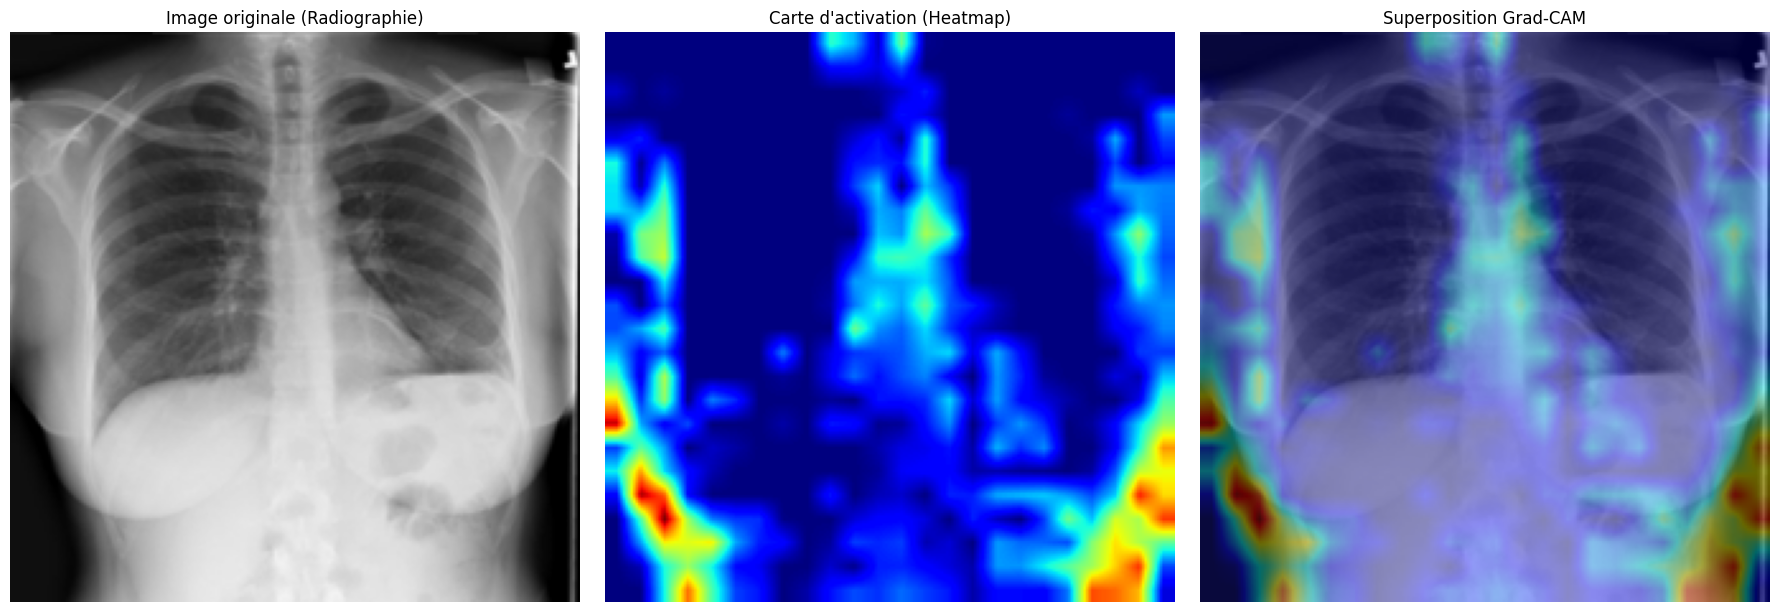

In [ ]:

normal_samples = val_gen_df[val_gen_df["target_str"] == "0"]
if not normal_samples.empty:
    # Prendre la première image saine disponible
    sample_path_normal = normal_samples.iloc[0]["filepath"]

    # Préparer l'image pour le modèle
    img_normal = tf.keras.preprocessing.image.load_img(sample_path_normal, target_size=(224, 224), color_mode="grayscale")
    img_array_normal = tf.keras.preprocessing.image.img_to_array(img_normal) / 255.0
    img_array_normal = np.expand_dims(img_array_normal, axis=0)

    # Prédire et s'assurer que le modèle est appelé
    pred_prob = opt_model.predict(img_array_normal)
    pred_class = int(pred_prob[0][0] > 0.5)
    print(f"Image sélectionnée : {sample_path_normal}")
    print(f"Prédiction du modèle : {pred_prob[0][0]:.4f} -> Classe : {pred_class} (0 = Non-COVID, 1 = COVID)")

    # Nom de la dernière couche de convolution
    last_conv_layer_name = [layer.name for layer in opt_model.layers if "conv2d" in layer.name][-1]

    # Générer la heatmap Grad-CAM
    heatmap_normal = make_gradcam_heatmap(img_array_normal, opt_model, last_conv_layer_name)

    # Afficher la superposition Grad-CAM
    print("\n--- Grad-CAM pour un cas Normal (Non-COVID) ---")
    display_gradcam(sample_path_normal, heatmap_normal)
else:
    print("Aucun échantillon Non-COVID trouvé dans le dataset de validation.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Image sélectionnée (COVID) : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/COVID/images/COVID-618.png
Probabilité prédite : 0.6424 -> Classe prédite : 1 (0 = Non-COVID, 1 = COVID)

--- Grad-CAM pour un cas Positif (COVID-19) ---


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 1))
  warnings.warn(msg)


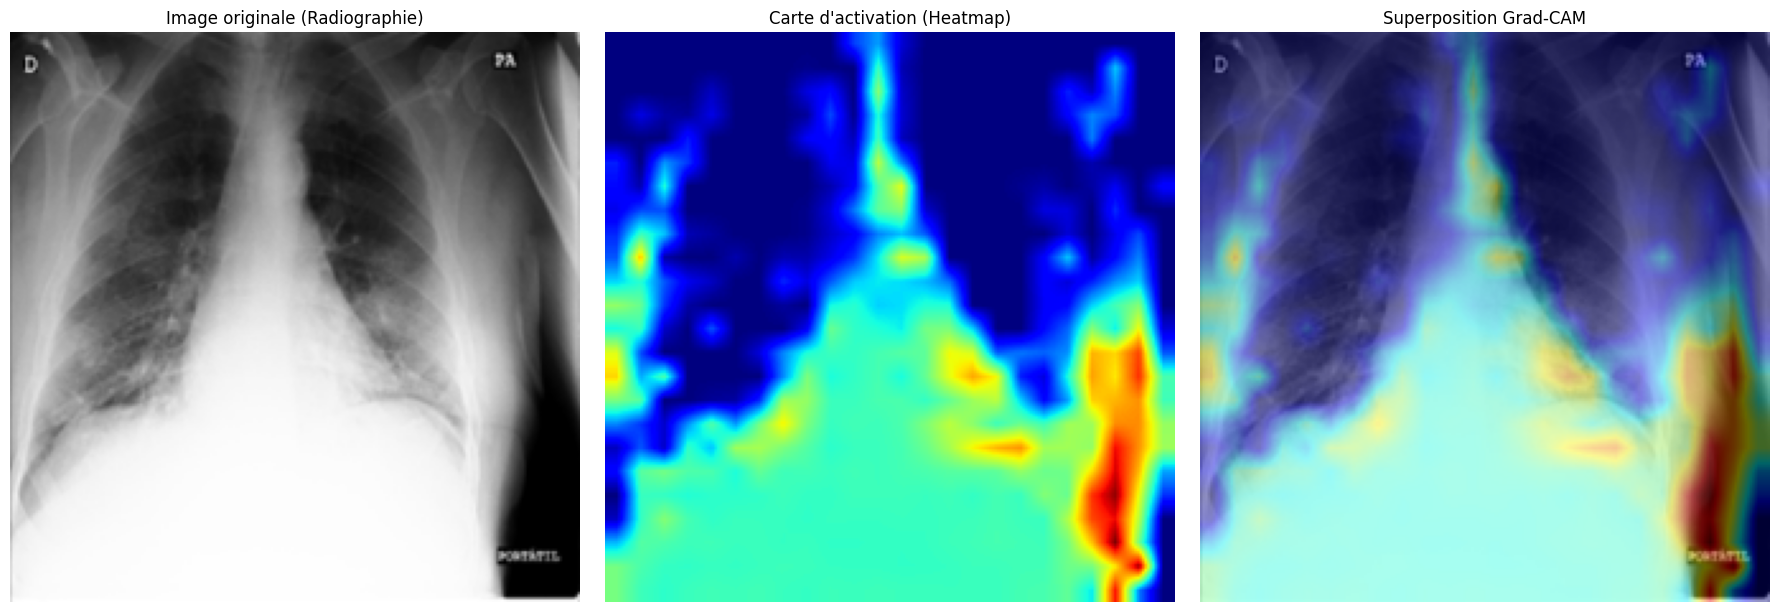

In [ ]:

covid_samples = val_gen_df[val_gen_df["target_str"] == "1"]
if not covid_samples.empty:
    # Nous prenons par exemple le premier échantillon COVID de validation disponible
    sample_path_covid = covid_samples.iloc[0]["filepath"]

    # Préparer l'image pour le modèle (224x224, niveaux de gris)
    img_covid = tf.keras.preprocessing.image.load_img(sample_path_covid, target_size=(224, 224), color_mode="grayscale")
    img_array_covid = tf.keras.preprocessing.image.img_to_array(img_covid) / 255.0
    img_array_covid = np.expand_dims(img_array_covid, axis=0)

    # 2. Prédiction de notre modèle CNN optimisé
    pred_prob_covid = opt_model.predict(img_array_covid)
    pred_class_covid = int(pred_prob_covid[0][0] > 0.5)
    print(f"Image sélectionnée (COVID) : {sample_path_covid}")
    print(f"Probabilité prédite : {pred_prob_covid[0][0]:.4f} -> Classe prédite : {pred_class_covid} (0 = Non-COVID, 1 = COVID)")

    # 3. Récupération de la dernière couche de convolution du modèle
    last_conv_layer_name = [layer.name for layer in opt_model.layers if "conv2d" in layer.name][-1]

    
    heatmap_covid = make_gradcam_heatmap(img_array_covid, opt_model, last_conv_layer_name)

    # 5. Affichage des résultats avec superposition
    print("\n--- Grad-CAM pour un cas Positif (COVID-19) ---")
    display_gradcam(sample_path_covid, heatmap_covid)
else:
    print("Aucun échantillon de test positif (COVID-19) n'a été trouvé dans le dataset de validation.")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 1))
  warnings.warn(msg)


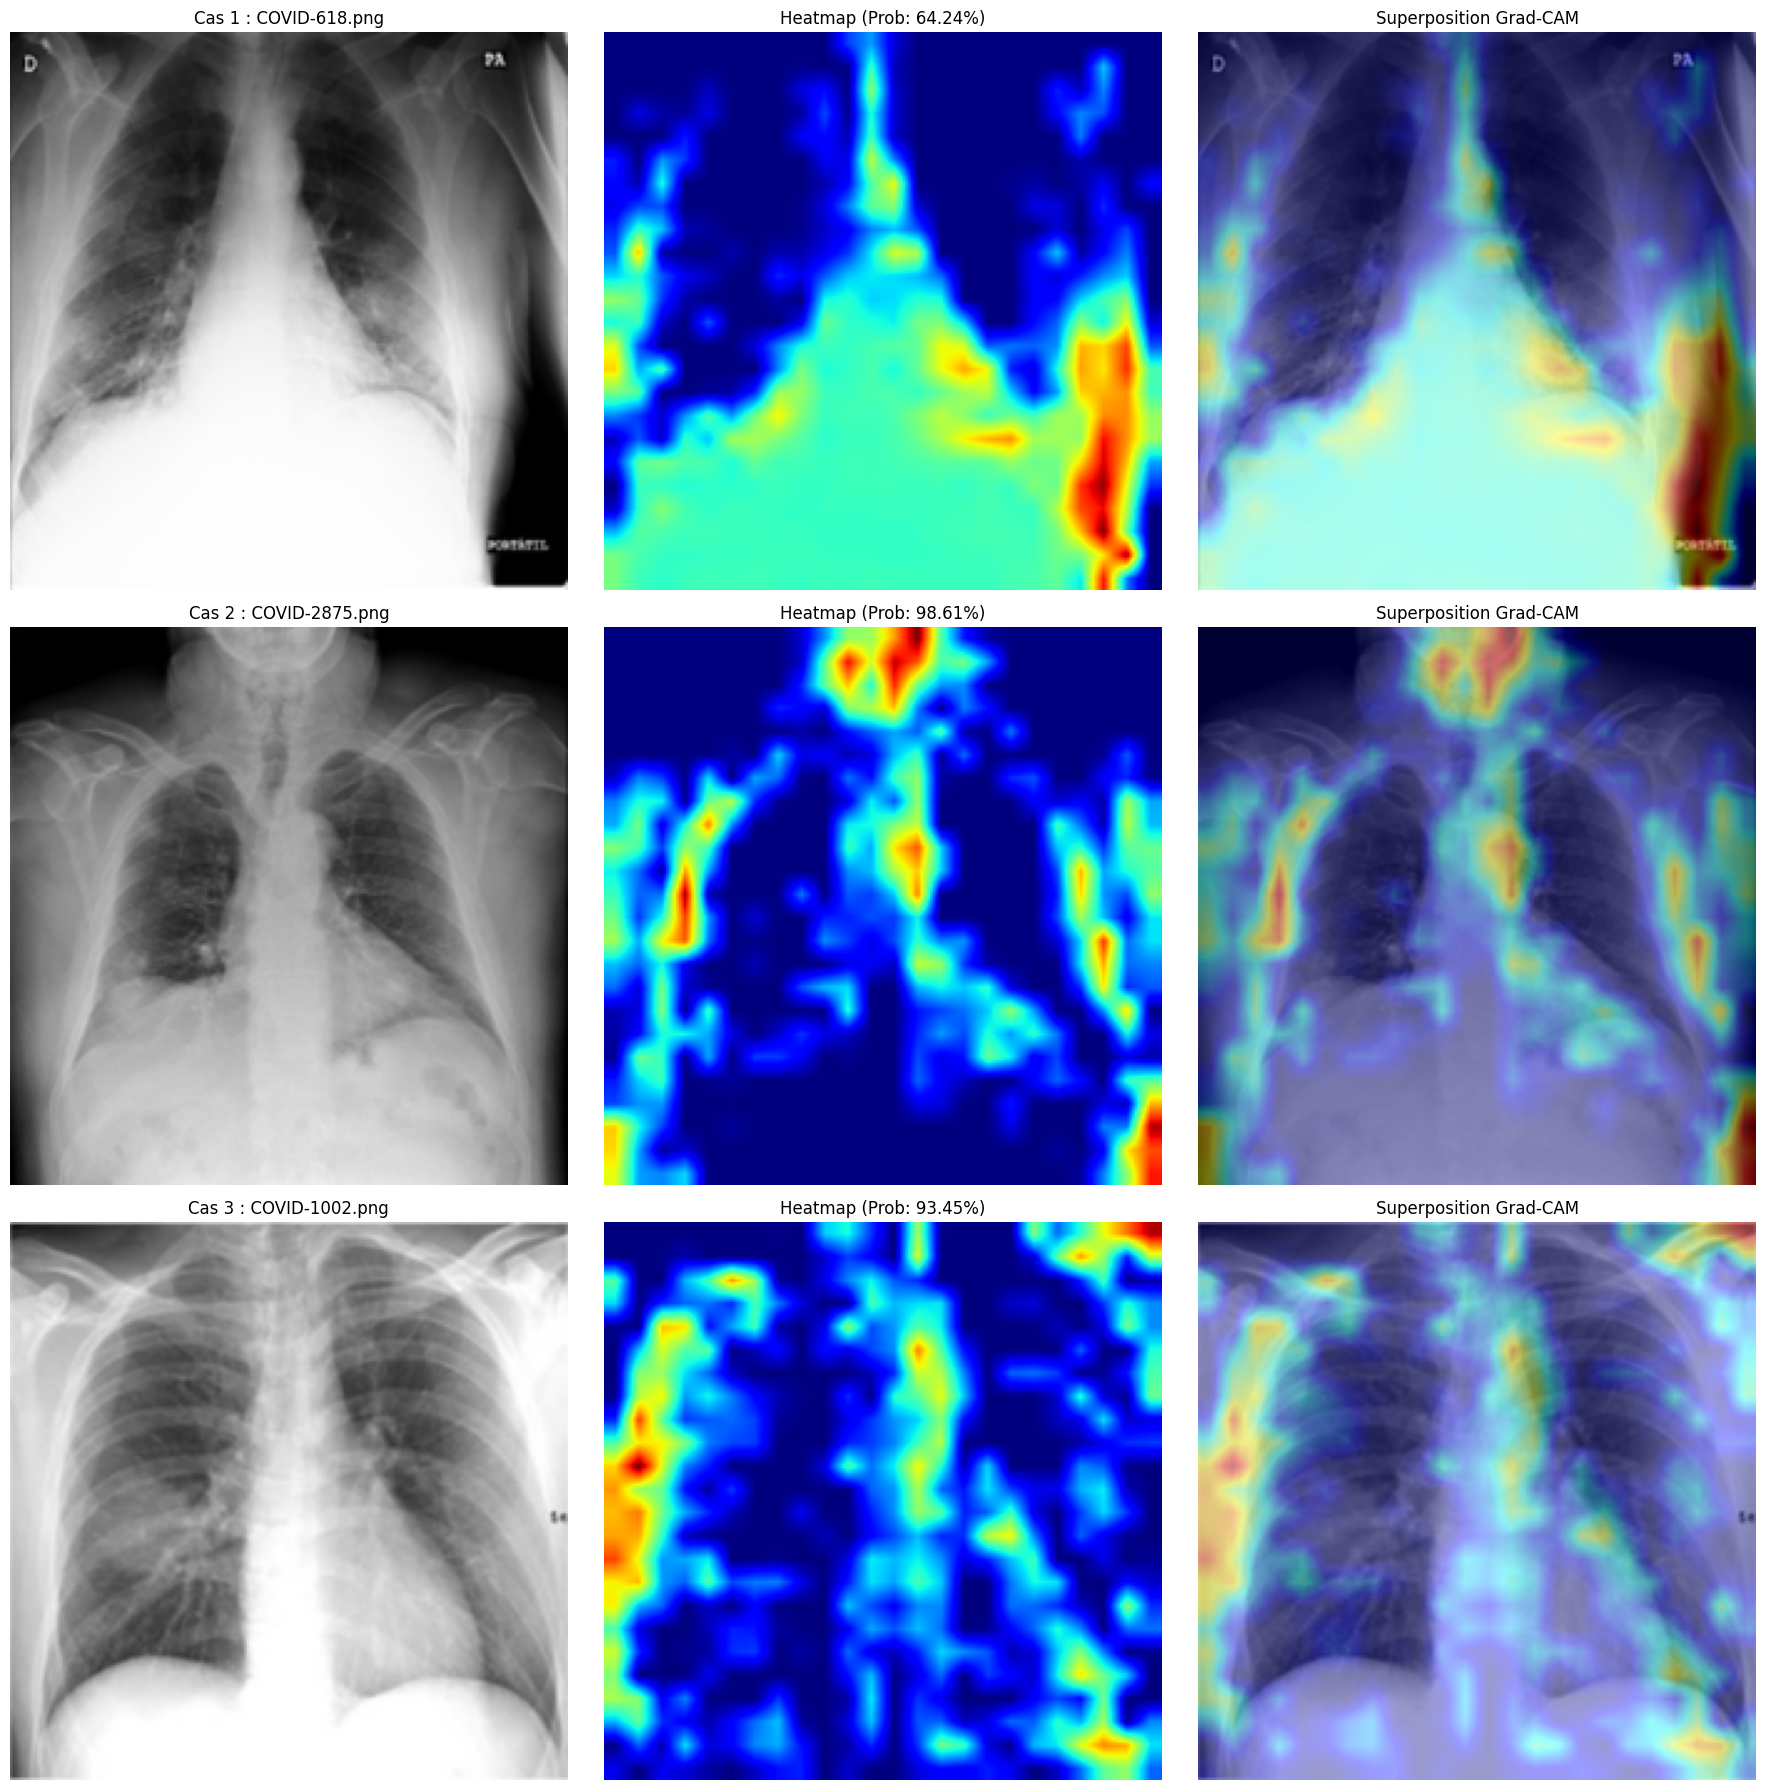

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

# 1. Sélectionner 3 cas COVID distincts de validation
covid_samples = val_gen_df[val_gen_df['target_str'] == '1']

if len(covid_samples) >= 3:
    selected_samples = covid_samples.iloc[:3]

    
    fig, axes = plt.subplots(3, 3, figsize=(18, 18))

    for i, (_, row) in enumerate(selected_samples.iterrows()):
        sample_path = row['filepath']
        filename = row['filename']

        # Préparation de l'image
        img = tf.keras.preprocessing.image.load_img(sample_path, target_size=(224, 224), color_mode='grayscale')
        img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
        img_array_expanded = np.expand_dims(img_array, axis=0)

        # Prédiction
        pred_prob = opt_model.predict(img_array_expanded, verbose=0)[0][0]

        # Générer le Grad-CAM
        last_conv_layer_name = [layer.name for layer in opt_model.layers if 'conv2d' in layer.name][-1]
        heatmap = make_gradcam_heatmap(img_array_expanded, opt_model, last_conv_layer_name)

        # Post-traitement de l'image pour la superposition
        original_img = cv2.imread(sample_path)
        original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
        original_img = cv2.resize(original_img, (224, 224))

        heatmap_resized = cv2.resize(heatmap, (original_img.shape[1], original_img.shape[0]))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

        superimposed_img = heatmap_color * 0.4 + original_img * 0.6
        superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

        # Affichage
        # Image Originale
        axes[i, 0].imshow(original_img)
        axes[i, 0].set_title(f"Cas {i+1} : {filename}")
        axes[i, 0].axis('off')

        # Carte d'activation
        axes[i, 1].imshow(heatmap_resized, cmap='jet')
        axes[i, 1].set_title(f"Heatmap (Prob: {pred_prob:.2%})")
        axes[i, 1].axis('off')

        # Superposition
        axes[i, 2].imshow(superimposed_img)
        axes[i, 2].set_title("Superposition Grad-CAM")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Il n'y a pas assez d'échantillons COVID dans le jeu de validation pour cette comparaison.")